# AIML Lab Exercise 3: Uniform Cost Search (UCS)
**Problem:** Find the cheapest route between two cities on the Romania road map (Russell & Norvig, *AIMA*)

Uniform Cost Search is an **uninformed search** strategy for **weighted graphs**. Instead of expanding the shallowest node (like BFS), it always expands the node with the **lowest path cost g(n)** using a **priority queue**. This guarantees that the first time the goal is expanded, the path to it is the cheapest one.

## 1. Import the required libraries

In [1]:
import heapq
from collections import deque
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Represent the weighted graph (Romania road map)
Each road is stored as `(city1, city2, distance in km)` and converted into an adjacency list.

In [2]:
edges = [
    ('Arad', 'Zerind', 75), ('Arad', 'Sibiu', 140), ('Arad', 'Timisoara', 118),
    ('Zerind', 'Oradea', 71), ('Oradea', 'Sibiu', 151), ('Timisoara', 'Lugoj', 111),
    ('Lugoj', 'Mehadia', 70), ('Mehadia', 'Drobeta', 75), ('Drobeta', 'Craiova', 120),
    ('Craiova', 'Rimnicu Vilcea', 146), ('Craiova', 'Pitesti', 138),
    ('Sibiu', 'Fagaras', 99), ('Sibiu', 'Rimnicu Vilcea', 80),
    ('Rimnicu Vilcea', 'Pitesti', 97), ('Fagaras', 'Bucharest', 211),
    ('Pitesti', 'Bucharest', 101), ('Bucharest', 'Giurgiu', 90),
    ('Bucharest', 'Urziceni', 85), ('Urziceni', 'Hirsova', 98), ('Hirsova', 'Eforie', 86),
    ('Urziceni', 'Vaslui', 142), ('Vaslui', 'Iasi', 92), ('Iasi', 'Neamt', 87),
]

# Undirected weighted graph as an adjacency list: {city: {neighbour: distance}}
graph = {}
for u, v, w in edges:
    graph.setdefault(u, {})[v] = w
    graph.setdefault(v, {})[u] = w

for city in sorted(graph):
    print(f"{city:15s} -> {graph[city]}")
print("\nNumber of cities:", len(graph))
print("Number of roads :", len(edges))

Arad            -> {'Zerind': 75, 'Sibiu': 140, 'Timisoara': 118}
Bucharest       -> {'Fagaras': 211, 'Pitesti': 101, 'Giurgiu': 90, 'Urziceni': 85}
Craiova         -> {'Drobeta': 120, 'Rimnicu Vilcea': 146, 'Pitesti': 138}
Drobeta         -> {'Mehadia': 75, 'Craiova': 120}
Eforie          -> {'Hirsova': 86}
Fagaras         -> {'Sibiu': 99, 'Bucharest': 211}
Giurgiu         -> {'Bucharest': 90}
Hirsova         -> {'Urziceni': 98, 'Eforie': 86}
Iasi            -> {'Vaslui': 92, 'Neamt': 87}
Lugoj           -> {'Timisoara': 111, 'Mehadia': 70}
Mehadia         -> {'Lugoj': 70, 'Drobeta': 75}
Neamt           -> {'Iasi': 87}
Oradea          -> {'Zerind': 71, 'Sibiu': 151}
Pitesti         -> {'Craiova': 138, 'Rimnicu Vilcea': 97, 'Bucharest': 101}
Rimnicu Vilcea  -> {'Craiova': 146, 'Sibiu': 80, 'Pitesti': 97}
Sibiu           -> {'Arad': 140, 'Oradea': 151, 'Fagaras': 99, 'Rimnicu Vilcea': 80}
Timisoara       -> {'Arad': 118, 'Lugoj': 111}
Urziceni        -> {'Bucharest': 85, 'Hirsova': 98, 

## 3. Visualize the road map with distances

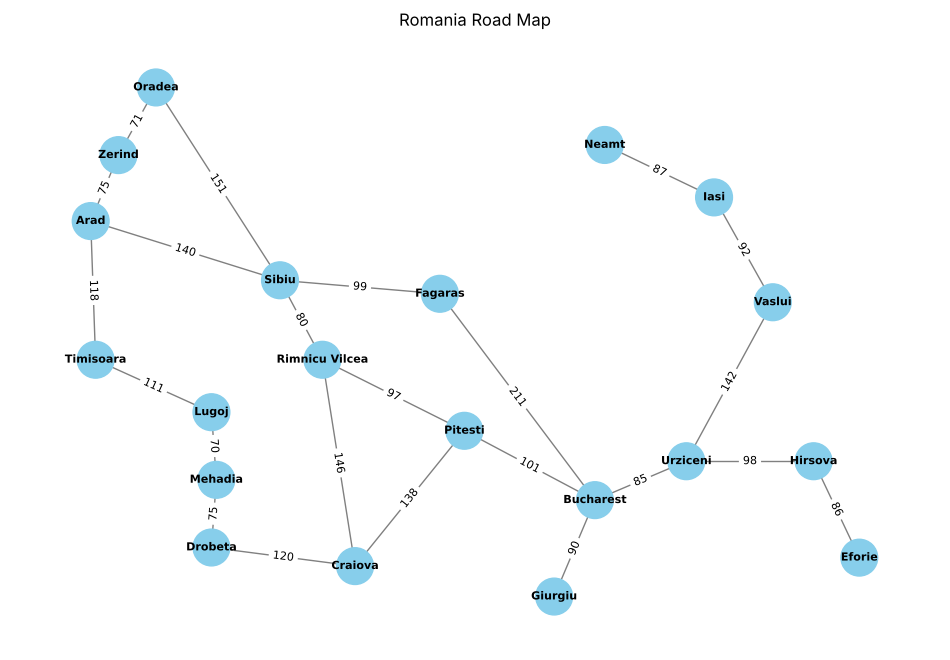

In [3]:
pos = {
    'Arad': (91, 492), 'Bucharest': (400, 327), 'Craiova': (253, 288), 'Drobeta': (165, 299),
    'Eforie': (562, 293), 'Fagaras': (305, 449), 'Giurgiu': (375, 270), 'Hirsova': (534, 350),
    'Iasi': (473, 506), 'Lugoj': (165, 379), 'Mehadia': (168, 339), 'Neamt': (406, 537),
    'Oradea': (131, 571), 'Pitesti': (320, 368), 'Rimnicu Vilcea': (233, 410),
    'Sibiu': (207, 457), 'Timisoara': (94, 410), 'Urziceni': (456, 350),
    'Vaslui': (509, 444), 'Zerind': (108, 531),
}

G = nx.Graph()
for u, v, w in edges:
    G.add_edge(u, v, weight=w)

def draw_map(path=None, title='Romania Road Map', node_labels=None):
    plt.figure(figsize=(12, 8))
    nx.draw_networkx_edges(G, pos, edge_color='gray')
    if path:
        nx.draw_networkx_edges(G, pos, edgelist=list(zip(path, path[1:])), edge_color='red', width=4)
    nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, 'weight'), font_size=8)
    colors = ['orange' if path and n in path else 'skyblue' for n in G.nodes]
    nx.draw_networkx_nodes(G, pos, node_color=colors, node_size=700)
    nx.draw_networkx_labels(G, pos, labels=node_labels, font_size=8, font_weight='bold')
    plt.title(title)
    plt.axis('off')
    plt.show()

draw_map()

## 4. Implement Uniform Cost Search
**Algorithm:**
1. Insert the start node into the priority queue with cost 0.
2. Pop the node with the **lowest path cost g(n)**.
3. If it is the goal, return the path and its cost (goal test is done on **expansion**, not on generation — this is what makes UCS optimal).
4. Otherwise mark it explored and push every neighbour with cost `g(n) + step cost`, if this is cheaper than any cost seen before for that neighbour.
5. Repeat until the queue is empty (goal unreachable).

In [4]:
def uniform_cost_search(graph, start, goal, trace=False):
    frontier = [(0, start, [start])]          # (path cost, node, path)
    best_cost = {start: 0}
    explored = set()
    steps = []

    while frontier:
        cost, node, path = heapq.heappop(frontier)
        if node in explored:
            continue                          # stale entry with a higher cost
        if trace:
            steps.append({'Step': len(steps) + 1, 'Expanded node': node, 'g(n)': cost,
                          'Frontier (node: cost)': ', '.join(f"{n}: {c}" for c, n, _ in sorted(frontier))})
        if node == goal:
            return path, cost, explored | {node}, pd.DataFrame(steps)
        explored.add(node)

        for neighbour, step_cost in graph[node].items():
            new_cost = cost + step_cost
            if neighbour not in explored and new_cost < best_cost.get(neighbour, float('inf')):
                best_cost[neighbour] = new_cost
                heapq.heappush(frontier, (new_cost, neighbour, path + [neighbour]))

    return None, float('inf'), explored, pd.DataFrame(steps)

print("UCS function defined.")

UCS function defined.


## 5. Find the cheapest path from Arad to Bucharest

In [5]:
path, cost, expanded, trace = uniform_cost_search(graph, 'Arad', 'Bucharest', trace=True)
print("Optimal path :", ' -> '.join(path))
print("Total cost   :", cost, "km")
print("Nodes expanded:", len(expanded))

Optimal path : Arad -> Sibiu -> Rimnicu Vilcea -> Pitesti -> Bucharest
Total cost   : 418 km
Nodes expanded: 13


## 6. Trace the order of node expansion
The table shows which node was popped from the priority queue at every step, its path cost, and the remaining frontier sorted by cost. Notice that **Bucharest first enters the frontier with cost 450 (via Fagaras)**, but UCS does not stop there — it keeps expanding cheaper nodes and later finds the cheaper route of **418 via Rimnicu Vilcea and Pitesti**.

In [6]:
pd.set_option('display.max_colwidth', None)
display(trace)

,Step,Expanded node,g(n),Frontier (node: cost)
0,1,Arad,0,
1,2,Zerind,75,"Timisoara: 118, Sibiu: 140"
2,3,Timisoara,118,"Sibiu: 140, Oradea: 146"
3,4,Sibiu,140,"Oradea: 146, Lugoj: 229"
4,5,Oradea,146,"Rimnicu Vilcea: 220, Lugoj: 229, Fagaras: 239"
5,6,Rimnicu Vilcea,220,"Lugoj: 229, Fagaras: 239"
6,7,Lugoj,229,"Fagaras: 239, Pitesti: 317, Craiova: 366"
7,8,Fagaras,239,"Mehadia: 299, Pitesti: 317, Craiova: 366"
8,9,Mehadia,299,"Pitesti: 317, Craiova: 366, Bucharest: 450"
9,10,Pitesti,317,"Craiova: 366, Drobeta: 374, Bucharest: 450"


## 7. Visualize the optimal path

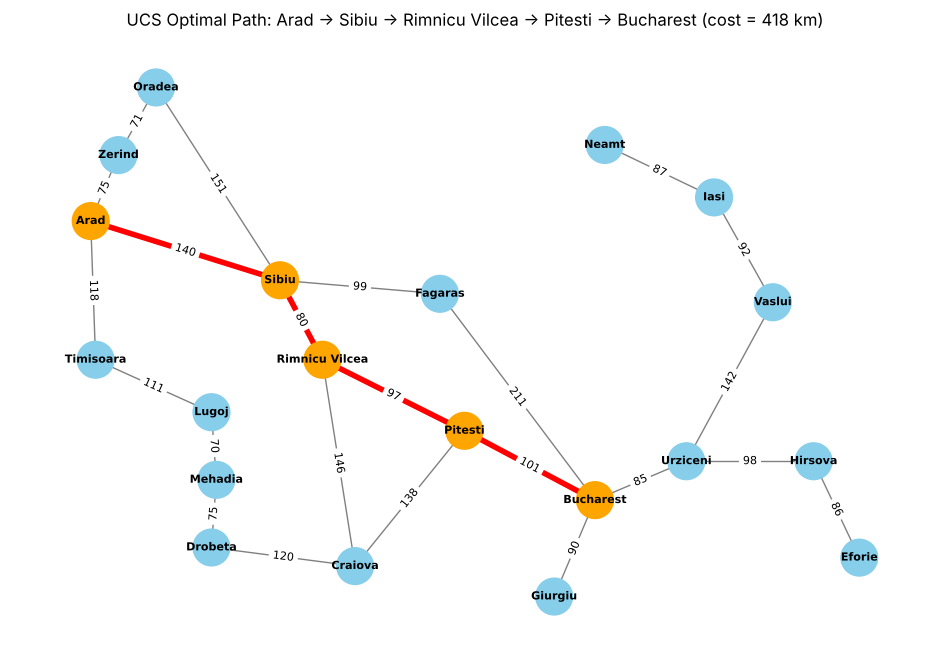

In [7]:
draw_map(path, title=f"UCS Optimal Path: {' -> '.join(path)} (cost = {cost} km)")

## 8. Compare UCS with BFS
BFS ignores the edge weights and returns the path with the **fewest roads**, which is not necessarily the **shortest distance**.

In [8]:
def bfs_path(graph, start, goal):
    parent = {start: None}
    queue = deque([start])
    while queue:
        node = queue.popleft()
        if node == goal:
            break
        for neighbour in graph[node]:
            if neighbour not in parent:
                parent[neighbour] = node
                queue.append(neighbour)
    path, node = [], goal
    while node is not None:
        path.append(node)
        node = parent[node]
    return path[::-1]

def path_cost(path):
    return sum(graph[a][b] for a, b in zip(path, path[1:]))

bfs_p = bfs_path(graph, 'Arad', 'Bucharest')
display(pd.DataFrame({
    'Path': [' -> '.join(bfs_p), ' -> '.join(path)],
    'Number of roads': [len(bfs_p) - 1, len(path) - 1],
    'Total distance (km)': [path_cost(bfs_p), cost],
}, index=['BFS', 'UCS']))

,Path,Number of roads,Total distance (km)
BFS,Arad -> Sibiu -> Fagaras -> Bucharest,3,450
UCS,Arad -> Sibiu -> Rimnicu Vilcea -> Pitesti -> Bucharest,4,418


**Interpretation:** BFS finds a path with only 3 roads but it is 450 km long. UCS uses 4 roads but the total distance is only 418 km, which is the true optimum.

## 9. Cheapest cost from Arad to every city
Running UCS for each destination gives the shortest road distance from Arad to all cities.

In [9]:
rows = []
for city in sorted(graph):
    p, c, exp, _ = uniform_cost_search(graph, 'Arad', city)
    rows.append({'Destination': city, 'Cost (km)': c, 'Nodes expanded': len(exp), 'Path': ' -> '.join(p)})
all_costs = pd.DataFrame(rows).sort_values('Cost (km)').reset_index(drop=True)
display(all_costs)

,Destination,Cost (km),Nodes expanded,Path
0,Arad,0,1,Arad
1,Zerind,75,2,Arad -> Zerind
2,Timisoara,118,3,Arad -> Timisoara
3,Sibiu,140,4,Arad -> Sibiu
4,Oradea,146,5,Arad -> Zerind -> Oradea
5,Rimnicu Vilcea,220,6,Arad -> Sibiu -> Rimnicu Vilcea
6,Lugoj,229,7,Arad -> Timisoara -> Lugoj
7,Fagaras,239,8,Arad -> Sibiu -> Fagaras
8,Mehadia,299,9,Arad -> Timisoara -> Lugoj -> Mehadia
9,Pitesti,317,10,Arad -> Sibiu -> Rimnicu Vilcea -> Pitesti


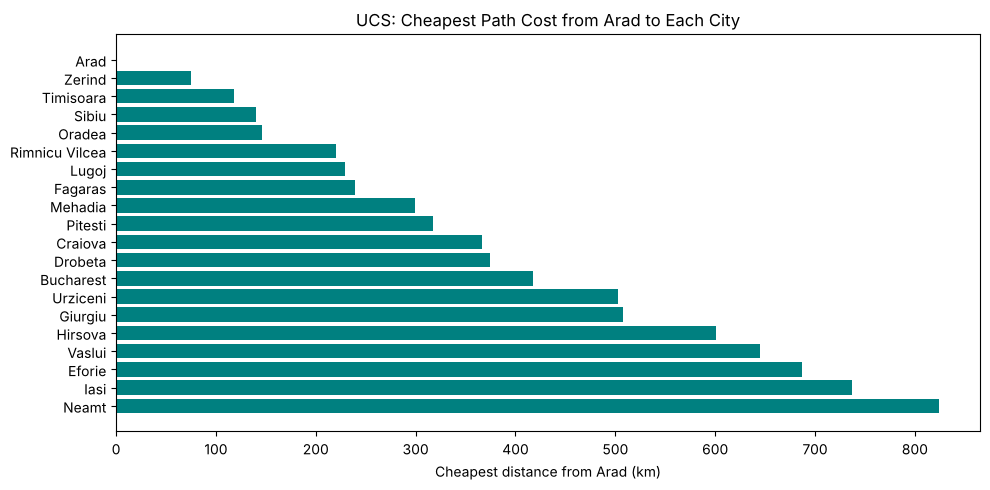

In [10]:
plt.figure(figsize=(10, 5))
plt.barh(all_costs['Destination'], all_costs['Cost (km)'], color='teal')
plt.xlabel('Cheapest distance from Arad (km)')
plt.title('UCS: Cheapest Path Cost from Arad to Each City')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 10. Test with other start and goal cities, and an unreachable goal

In [11]:
for s, g in [('Timisoara', 'Neamt'), ('Oradea', 'Eforie'), ('Lugoj', 'Fagaras')]:
    p, c, exp, _ = uniform_cost_search(graph, s, g)
    print(f"{s} -> {g}: cost = {c} km, nodes expanded = {len(exp)}, path = {' -> '.join(p)}")

graph['London'] = {}   # isolated node, not connected to any Romanian city
p, c, exp, _ = uniform_cost_search(graph, 'Arad', 'London')
print(f"\nArad -> London: path = {p}, cost = {c}, nodes expanded = {len(exp)} (goal unreachable)")
del graph['London']

Timisoara -> Neamt: cost = 942 km, nodes expanded = 20, path = Timisoara -> Arad -> Sibiu -> Rimnicu Vilcea -> Pitesti -> Bucharest -> Urziceni -> Vaslui -> Iasi -> Neamt
Oradea -> Eforie: cost = 698 km, nodes expanded = 18, path = Oradea -> Sibiu -> Rimnicu Vilcea -> Pitesti -> Bucharest -> Urziceni -> Hirsova -> Eforie
Lugoj -> Fagaras: cost = 468 km, nodes expanded = 12, path = Lugoj -> Timisoara -> Arad -> Sibiu -> Fagaras

Arad -> London: path = None, cost = inf, nodes expanded = 20 (goal unreachable)


## 11. Properties of Uniform Cost Search
| Property | Uniform Cost Search |
|---|---|
| Data structure | Priority queue ordered by path cost g(n) |
| Complete? | Yes, if every step cost ≥ ε > 0 |
| Optimal? | Yes — nodes are expanded in increasing order of g(n) |
| Time complexity | O(b^(1 + ⌊C*/ε⌋)) |
| Space complexity | O(b^(1 + ⌊C*/ε⌋)) |
| Relation to other algorithms | Equivalent to BFS when all step costs are equal; same idea as Dijkstra's algorithm |

where *C\** is the cost of the optimal solution and *ε* is the smallest step cost.

## 12. Documentation summary
1. Represented the Romania road map as a weighted adjacency list and visualized it
2. Implemented Uniform Cost Search using a priority queue (`heapq`) with the goal test on expansion
3. Found the optimal path from Arad to Bucharest and traced every node expansion
4. Visualized the optimal path on the map
5. Compared UCS with BFS to show that fewest edges ≠ lowest cost
6. Computed the cheapest cost from Arad to every city
7. Tested other source/destination pairs and an unreachable goal

**Result:** Uniform Cost Search was implemented successfully. The optimal route from Arad to Bucharest is **Arad → Sibiu → Rimnicu Vilcea → Pitesti → Bucharest** with a total cost of **418 km**.